# 🍔 TPI Python ETL: Pipeline ETL & Inteligencia de Mercado (Food Delivery)



## 🎯 Contexto de negocio
Una startup de Food Delivery quiere expandirse en Estados Unidos. Antes de elegir ciudades, el directorio necesita saber **cómo operan los competidores, qué ciudades concentran más restaurantes y cómo se comportan los precios**.

## 🏗️ Arquitectura del pipeline
| Fase | Qué hacemos | Herramienta |
|---|---|---|
| 📥 **EXTRACT** | Leer los CSV crudos y diagnosticar su calidad | `pandas` |
| 🧹 **TRANSFORM** | Mapear precios, separar direcciones, limpiar y castear, reducir el dataset y cruzar | `pandas` |
| 💾 **LOAD** | Persistir la tabla final en SQLite | `SQLAlchemy` |
| 📊 **BI** | 4 preguntas del CEO con SQL + gráficos | `pd.read_sql`, `seaborn`, `matplotlib` |

> ℹ️ **Nota sobre los datos:** los CSV reales usan nombres de columna en inglés (`price_range`, `full_address`, `price`). El enunciado los nombra en español, por eso en la fase TRANSFORM se renombran a `rango_de_precios`, `direccion_completa` y `precio`. Además, `restaurant-menus.csv` viene **partido en 10 archivos** (`restaurant_menus_parte_N.csv`); se leen todos y se concatenan.

## ⚙️ 0. Configuración e imports


In [1]:
# ── Librerías ─────────────────────────────────────────────
import glob                      # búsqueda de archivos por patrón
import pandas as pd              # manipulación de datos
from sqlalchemy import create_engine, text   # conexión a SQLite y ejecución de SQL
import matplotlib.pyplot as plt  # gráficos
import seaborn as sns            # gráficos estadísticos

# ── Rutas de entrada / salida ─────────────────────────────
RUTA_RESTAURANTES = "data/restaurants.csv"
PATRON_MENUS      = "data/restaurant-menus/restaurant_menus_parte_*.csv"
RUTA_DB           = "sqlite:///delivery_insights.db"

# ── Estilo global de los gráficos ─────────────────────────
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_columns", 30)
print("✅ Entorno listo")

✅ Entorno listo


# 📥 FASE 1 · EXTRACT: Extracción y diagnóstico
## 1.1 📂 Carga de los archivos crudos

In [2]:
# Catálogo de restaurantes (un único CSV)
df_restaurantes = pd.read_csv(RUTA_RESTAURANTES)

# Menús: el archivo viene troceado en partes; las leemos todas y las unimos
archivos_menus = sorted(glob.glob(PATRON_MENUS))
print(f"📄 Partes de menú encontradas: {len(archivos_menus)}")
df_menus = pd.concat((pd.read_csv(f) for f in archivos_menus), ignore_index=True)

print("✅ df_restaurantes y df_menus cargados")

📄 Partes de menú encontradas: 10
✅ df_restaurantes y df_menus cargados


## 1.2 🔎 Data Profiling: dimensiones, tipos y nulos

In [3]:
def perfilar(df, nombre):
    # Imprime el diagnóstico inicial de un DataFrame
    print("=" * 60)
    print(f"🔎 {nombre}")
    print("=" * 60)
    print(f"📐 Dimensiones (.shape): {df.shape}  → {df.shape[0]:,} filas × {df.shape[1]} columnas")
    print("\n🧬 Tipos de datos (.dtypes):")
    print(df.dtypes.to_string())
    print("\n❓ Valores nulos por columna:")
    nulos = df.isna().sum()
    print(pd.DataFrame({"nulos": nulos, "% nulos": (nulos / len(df) * 100).round(1)}).to_string())
    print()

perfilar(df_restaurantes, "df_restaurantes")
perfilar(df_menus, "df_menus")

🔎 df_restaurantes
📐 Dimensiones (.shape): (63469, 11)  → 63,469 filas × 11 columnas

🧬 Tipos de datos (.dtypes):
id                int64
position          int64
name                str
score           float64
ratings         float64
category            str
price_range         str
full_address        str
zip_code            str
lat             float64
lng             float64

❓ Valores nulos por columna:
              nulos  % nulos
id                0      0.0
position          0      0.0
name              0      0.0
score         28167     44.4
ratings       28167     44.4
category         85      0.1
price_range   10617     16.7
full_address    453      0.7
zip_code        517      0.8
lat               0      0.0
lng               0      0.0

🔎 df_menus
📐 Dimensiones (.shape): (836350, 5)  → 836,350 filas × 5 columnas

🧬 Tipos de datos (.dtypes):
restaurant_id    int64
category           str
name               str
description        str
price              str

❓ Valores nulos por co

In [4]:
# Vista rápida de las primeras filas de cada tabla
display(df_restaurantes.head(3))
display(df_menus.head(3))

,id,position,name,score,ratings,category,price_range,full_address,zip_code,lat,lng
0,1,19,PJ Fresh (224 Daniel Payne Drive),NaN,NaN,"Burgers, American, Sandwiches",$,"224 Daniel Payne Drive, Birmingham, AL, 35207",35207,33.562365,-86.830703
1,2,9,J' ti`'z Smoothie-N-Coffee Bar,NaN,NaN,"Coffee and Tea, Breakfast and Brunch, Bubble Tea",NaN,"1521 Pinson Valley Parkway, Birmingham, AL, 35217",35217,33.583640,-86.773330
2,3,6,Philly Fresh Cheesesteaks (541-B Graymont Ave),NaN,NaN,"American, Cheesesteak, Sandwiches, Alcohol",$,"541-B Graymont Ave, Birmingham, AL, 35204",35204,33.509800,-86.854640


,restaurant_id,category,name,description,price
0,1,Extra Large Pizza,Extra Large Meat Lovers,Whole pie.,15.99 USD
1,1,Extra Large Pizza,Extra Large Supreme,Whole pie.,15.99 USD
2,1,Extra Large Pizza,Extra Large Pepperoni,Whole pie.,14.99 USD


### 🧾 Hallazgos del diagnóstico
- **`df_restaurantes`**: ~44 % de los restaurantes **no tiene `score` ni `ratings`** y ~17 % no tiene `rango_de_precios` → habrá que filtrar. `price_range` contiene además un valor anómalo (una cadena de 17 símbolos `$`) que no pertenece a la escala de 1 a 4.
- **`full_address`** tiene el formato `calle, ciudad, estado, zip`, pero algunas calles contienen comas (hasta 12 fragmentos), así que el split debe ser cuidadoso.
- **`df_menus`**: `price` es texto (`"15.99 USD"`); hay ~37 mil precios en cero (más 2 negativos) y filas duplicadas. La columna `category` existe en **ambas** tablas (ojo al cruzar).

# 🧹 FASE 2 · TRANSFORM: Limpieza e ingeniería de características
## 2.1 🏷️ Estandarización de nombres de columnas
Se alinean los nombres con el enunciado y se evita el choque de la columna `category` entre ambas tablas.

In [5]:
df_restaurantes = df_restaurantes.rename(columns={
    "price_range":  "rango_de_precios",
    "full_address": "direccion_completa",
})
df_menus = df_menus.rename(columns={
    "category": "categoria_menu",   # evita colisión con restaurants.category al hacer el merge
    "name":     "nombre_plato",
})
print("✅ Columnas renombradas")
print("restaurantes:", list(df_restaurantes.columns))
print("menus       :", list(df_menus.columns))

✅ Columnas renombradas
restaurantes: ['id', 'position', 'name', 'score', 'ratings', 'category', 'rango_de_precios', 'direccion_completa', 'zip_code', 'lat', 'lng']
menus       : ['restaurant_id', 'categoria_menu', 'nombre_plato', 'description', 'price']


## 2.2 🍽️ `df_restaurantes`
### 💲 a) Mapeo de precios (símbolos → texto legible)

In [6]:
mapa_precios = {
    "$":    "Económico",
    "$$":   "Moderadamente caro",
    "$$$":  "Caro",
    "$$$$": "Muy caro",
}

print("Antes :", df_restaurantes["rango_de_precios"].value_counts(dropna=False).to_dict())

# .map() devuelve NaN para lo que no está en el diccionario (nulos y el valor anómalo de 17 '$')
df_restaurantes["rango_de_precios"] = df_restaurantes["rango_de_precios"].map(mapa_precios)

# Los restaurantes sin dato de precio se etiquetan explícitamente para no perderlos de la distribución
df_restaurantes["rango_de_precios"] = df_restaurantes["rango_de_precios"].fillna("Sin información")

print("Después:", df_restaurantes["rango_de_precios"].value_counts().to_dict())

Antes : {'$': 37637, '$$': 14952, nan: 10617, '$$$': 237, '$$$$': 25, '$$$$$$$$$$$$$$$$$': 1}
Después: {'Económico': 37637, 'Moderadamente caro': 14952, 'Sin información': 10618, 'Caro': 237, 'Muy caro': 25}


### 📍 b) Desanidado de ubicaciones (Split)
`direccion_completa` = `calle, ciudad, estado, zip`.
Usamos **`.str.rsplit(',', n=3, expand=True)`** (la variante de `.str.split` que corta **desde la derecha**): así las 4 últimas partes siempre son *ciudad, estado, zip* y cualquier coma dentro de la calle (p. ej. `"100 Main St, Suite 5"`) queda dentro de `calle`. Con un `split(',')` simple esas direcciones generarían hasta 12 columnas y desplazarían la ciudad.

In [7]:
# Cortamos desde la derecha: [calle] [ciudad] [estado] [zip]
partes = df_restaurantes["direccion_completa"].str.rsplit(",", n=3, expand=True)

df_restaurantes["calle"]      = partes[0].str.strip()
df_restaurantes["ciudad"]     = partes[1].str.strip()          # .str.strip() quita espacios ocultos
df_restaurantes["estado_zip"] = partes[2].str.strip() + ", " + partes[3].str.strip()

# La dirección original ya no aporta información: la eliminamos para ahorrar memoria
df_restaurantes = df_restaurantes.drop(columns="direccion_completa")

print("🏙️ Ciudades únicas:", df_restaurantes["ciudad"].nunique())
print("❓ Restaurantes sin dirección (ciudad nula):", df_restaurantes["ciudad"].isna().sum())
display(df_restaurantes[["name", "calle", "ciudad", "estado_zip"]].head(5))

🏙️ Ciudades únicas: 2280
❓ Restaurantes sin dirección (ciudad nula): 453


,name,calle,ciudad,estado_zip
0,PJ Fresh (224 Daniel Payne Drive),224 Daniel Payne Drive,Birmingham,"AL, 35207"
1,J' ti`'z Smoothie-N-Coffee Bar,1521 Pinson Valley Parkway,Birmingham,"AL, 35217"
2,Philly Fresh Cheesesteaks (541-B Graymont Ave),541-B Graymont Ave,Birmingham,"AL, 35204"
3,Papa Murphy's (1580 Montgomery Highway),1580 Montgomery Highway,Hoover,"AL, 35226"
4,Nelson Brothers Cafe (17th St N),314 17th St N,Birmingham,"AL, 35203"


### ⭐ c) Filtro de calidad
Se eliminan restaurantes **sin puntaje (nulo) o con puntaje 0** y se estandariza `category` a minúsculas.

In [8]:
n_antes = len(df_restaurantes)

df_restaurantes = df_restaurantes[df_restaurantes["score"].notna() & (df_restaurantes["score"] != 0)].copy()
df_restaurantes["category"] = (df_restaurantes["category"]
                               .str.lower()
                               .str.replace("&amp;", "&", regex=False)   # entidad HTML residual del scraping
                               .str.strip())

print(f"Restaurantes antes : {n_antes:,}")
print(f"Restaurantes después: {len(df_restaurantes):,}  (eliminados: {n_antes - len(df_restaurantes):,})")
display(df_restaurantes[["name", "score", "ratings", "category", "rango_de_precios", "ciudad"]].head(5))

Restaurantes antes : 63,469
Restaurantes después: 35,302  (eliminados: 28,167)


,name,score,ratings,category,rango_de_precios,ciudad
4,Nelson Brothers Cafe (17th St N),4.7,22.0,"breakfast and brunch, burgers, sandwiches",Sin información,Birmingham
6,Jinsei Sushi,4.7,63.0,"sushi, asian, japanese",Económico,Birmingham
13,Panera (521 Fieldstown Road),4.6,44.0,"breakfast and brunch, salad, sandwich, family ...",Económico,Gardendale
15,Jeni's Splendid Ice Cream (Pepper Place),5.0,20.0,"ice cream & frozen yogurt, comfort food, desserts",Caro,Birmingham
18,Falafel Cafe,4.9,48.0,"middle eastern, mediterranean, vegetarian, gre...",Económico,Birmingham


## 2.3 🍕 `df_menus`
### 💵 a) Limpieza y casteo del precio (`"15,99 USD"` → `15.99`)
Se quita `" USD"`, se reemplaza la coma por punto y se castea a `float`. Se usa `pd.to_numeric(errors="coerce")` para que cualquier valor mal formado (p. ej. un precio sin `USD`) no rompa el pipeline.

In [9]:
print("Ejemplos originales:", df_menus["price"].head(3).tolist())

df_menus["precio"] = pd.to_numeric(
    df_menus["price"]
        .str.replace(" USD", "", regex=False)   # quita el sufijo de moneda
        .str.replace(",", ".", regex=False)     # coma decimal → punto
        .str.strip(),
    errors="coerce",                            # lo no convertible queda NaN
)
df_menus = df_menus.drop(columns="price")       # ya no necesitamos el texto original

# Limpieza de entidades HTML del scraping ("&amp;" → "&") en columnas de texto
for col in ["categoria_menu", "nombre_plato"]:
    df_menus[col] = df_menus[col].str.replace("&amp;", "&", regex=False)

print("Ejemplos casteados :", df_menus["precio"].head(3).tolist())
print("Tipo resultante    :", df_menus["precio"].dtype)

Ejemplos originales: ['15.99 USD', '15.99 USD', '14.99 USD']
Ejemplos casteados : [15.99, 15.99, 14.99]
Tipo resultante    : float64


### 🗑️ b) Eliminar precios nulos / cero (y negativos) + duplicados
El enunciado pide eliminar precios `0.0` o nulos. Al perfilar aparecieron además **2 precios negativos**, que tampoco son precios de venta válidos, por lo que se descartan con la misma regla (`precio > 0`). También se eliminan filas 100 % duplicadas.

In [10]:
n_antes = len(df_menus)
print(f"Precios nulos: {df_menus['precio'].isna().sum():,} | cero: {(df_menus['precio'] == 0).sum():,} | negativos: {(df_menus['precio'] < 0).sum():,}")

df_menus = df_menus[df_menus["precio"].notna() & (df_menus["precio"] > 0)]
n_dups = df_menus.duplicated().sum()
df_menus = df_menus.drop_duplicates().reset_index(drop=True)

print(f"\nÍtems antes  : {n_antes:,}")
print(f"Duplicados   : {n_dups:,}")
print(f"Ítems después: {len(df_menus):,}")
display(df_menus["precio"].describe().round(2).to_frame().T)

Precios nulos: 0 | cero: 37,551 | negativos: 2

Ítems antes  : 836,350
Duplicados   : 2,537
Ítems después: 796,260


,count,mean,std,min,25%,50%,75%,max
precio,796260.0,10.35,11.56,0.01,4.39,8.38,13.19,1099.99


## 2.4 🧠 Optimización y cruce (control de memoria RAM)
### ✂️ a) Reducción estratégica: solo restaurantes consolidados (> 100 calificaciones)

In [11]:
mem_antes = df_restaurantes.memory_usage(deep=True).sum() / 1e6

df_restaurantes_filtrado = df_restaurantes[df_restaurantes["ratings"] > 100].copy()
mem_despues = df_restaurantes_filtrado.memory_usage(deep=True).sum() / 1e6

print(f"🍽️ Restaurantes con puntaje válido : {len(df_restaurantes):,}  ({mem_antes:.1f} MB)")
print(f"🏆 Restaurantes consolidados (>100): {len(df_restaurantes_filtrado):,}  ({mem_despues:.1f} MB)")
print(f"📉 Reducción: {(1 - len(df_restaurantes_filtrado) / len(df_restaurantes)):.1%} de las filas")

🍽️ Restaurantes con puntaje válido : 35,302  (18.9 MB)
🏆 Restaurantes consolidados (>100): 8,702  (4.7 MB)
📉 Reducción: 75.3% de las filas


### 🔗 b) INNER JOIN → `df_master`
Se cruza por el ID del restaurante (`id` en restaurantes ↔ `restaurant_id` en menús). El **inner join** conserva solo los restaurantes consolidados que además tienen menú cargado. Se descarta `description` (texto largo, ~24 % nulo, sin uso analítico) para aligerar el DataFrame.

In [12]:
df_menus_ligero = df_menus.drop(columns="description")

df_master = pd.merge(
    df_restaurantes_filtrado,
    df_menus_ligero,
    how="inner",
    left_on="id",
    right_on="restaurant_id",
    validate="one_to_many",      # garantiza que cada restaurante es único en el lado izquierdo
).drop(columns="restaurant_id")  # redundante con 'id'

print(f"✅ df_master: {df_master.shape[0]:,} filas × {df_master.shape[1]} columnas")
print(f"🍽️ Restaurantes únicos en df_master: {df_master['id'].nunique():,}")
print(f"💾 Memoria: {df_master.memory_usage(deep=True).sum() / 1e6:.1f} MB")
display(df_master.head(5))

✅ df_master: 63,186 filas × 16 columnas
🍽️ Restaurantes únicos en df_master: 671
💾 Memoria: 42.7 MB


,id,position,name,score,ratings,category,rango_de_precios,zip_code,lat,lng,calle,ciudad,estado_zip,categoria_menu,nombre_plato,precio
0,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,"WI, 53221",Picked for you,Spring Roll,6.99
1,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,"WI, 53221",Picked for you,Egg Roll,6.50
2,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,"WI, 53221",Picked for you,Grilled Pork,9.50
3,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,"WI, 53221",Picked for you,House Special,10.95
4,1739,21,Pho Cali Noodle House,4.4,200.0,"vietnamese, noodles, sandwich, asian",Económico,53221,42.958143,-87.94815,4756 S 27th St,Milwaukee,"WI, 53221",Picked for you,Rice Noodle with Rare Steak,10.95


In [13]:
# Sanidad del cruce: sin nulos en las columnas clave del análisis
print(df_master[["id", "score", "ratings", "rango_de_precios", "ciudad", "precio"]].isna().sum().to_string())

id                    0
score                 0
ratings               0
rango_de_precios      0
ciudad              200
precio                0


# 💾 FASE 3 · LOAD: Carga a SQLite
Se crea el motor con `create_engine` sobre el archivo local `delivery_insights.db` y se carga `df_master` en la tabla `master_food_data`.

In [14]:
engine = create_engine(RUTA_DB)

df_master.to_sql(
    "master_food_data",
    con=engine,
    if_exists="replace",   # reejecutar el notebook no duplica datos
    index=False,           # no guardamos el índice de pandas
    chunksize=10_000,      # inserción por lotes para cuidar la memoria
)
print("✅ Tabla 'master_food_data' cargada en delivery_insights.db")

✅ Tabla 'master_food_data' cargada en delivery_insights.db


In [15]:
# Verificación de la carga directamente desde SQL
with engine.connect() as conn:
    print("Filas en la tabla:", pd.read_sql(text("SELECT COUNT(*) AS filas FROM master_food_data"), conn).iloc[0, 0])
    display(pd.read_sql(text("PRAGMA table_info(master_food_data)"), conn)[["name", "type"]].T)

Filas en la tabla: 63186


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
name,id,position,name,score,ratings,category,rango_de_precios,zip_code,lat,lng,calle,ciudad,estado_zip,categoria_menu,nombre_plato,precio
type,INTEGER,INTEGER,TEXT,REAL,REAL,TEXT,TEXT,TEXT,REAL,REAL,TEXT,TEXT,TEXT,TEXT,TEXT,REAL


# 📊 FASE 4 · BI: Reporte al CEO (SQL + Visualización)


> ⚠️ **importante:** `master_food_data` tiene **una fila por plato**, no por restaurante. Para contar o promediar *restaurantes* se usa `COUNT(DISTINCT id)` y `SELECT DISTINCT`; si no, los restaurantes con menús grandes pesarían más y los resultados quedarían inflados.

In [16]:
# Helper: imprime el query y devuelve el resultado como DataFrame
def ejecutar_query(query):
    print("🧾 QUERY EJECUTADO:\n" + query.strip() + "\n")
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)

# Paleta coherente para todo el reporte
COLOR_PRINCIPAL = "#E4572E"   # naranja delivery
COLOR_NEUTRO    = "#B8B8B8"

## 🌎 Pregunta 1 · Penetración geográfica
**¿Cuáles son las 5 ciudades con más restaurantes consolidados?**

In [17]:
query_1 = '''
SELECT ciudad,
       COUNT(DISTINCT id) AS total_restaurantes
FROM master_food_data
WHERE ciudad IS NOT NULL
GROUP BY ciudad
ORDER BY total_restaurantes DESC, ciudad ASC
LIMIT 5;
'''
df_q1 = ejecutar_query(query_1)
display(df_q1)

🧾 QUERY EJECUTADO:
SELECT ciudad,
       COUNT(DISTINCT id) AS total_restaurantes
FROM master_food_data
WHERE ciudad IS NOT NULL
GROUP BY ciudad
ORDER BY total_restaurantes DESC, ciudad ASC
LIMIT 5;


,ciudad,total_restaurantes
0,Milwaukee,123
1,Seattle,119
2,Lynnwood,42
3,Everett,32
4,Bellevue,30


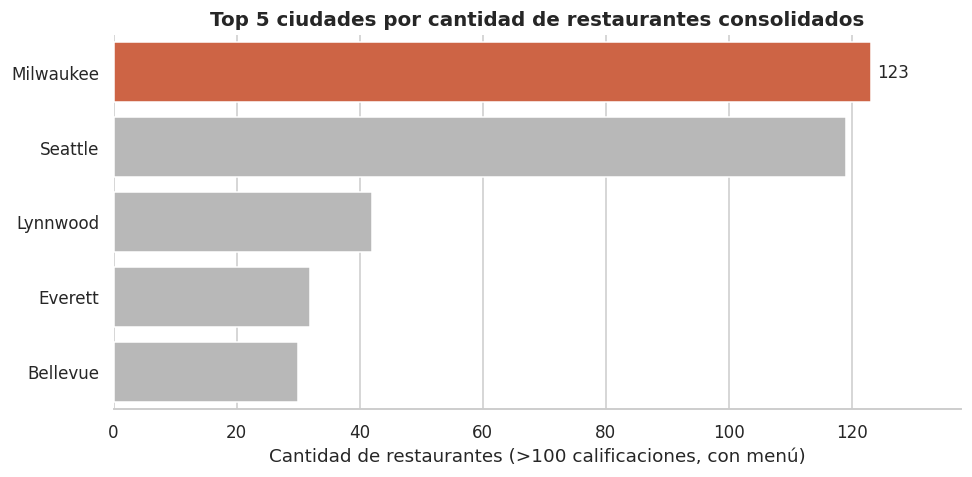

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df_q1, y="ciudad", x="total_restaurantes", hue="ciudad", palette=[COLOR_PRINCIPAL] + [COLOR_NEUTRO] * 4, legend=False, ax=ax)
ax.bar_label(ax.containers[0], padding=4, fontsize=11)
ax.set_title("Top 5 ciudades por cantidad de restaurantes consolidados")
ax.set_xlabel("Cantidad de restaurantes (>100 calificaciones, con menú)")
ax.set_ylabel("")
ax.set_xlim(0, df_q1["total_restaurantes"].max() * 1.12)
sns.despine(left=True)
plt.tight_layout()
plt.show()

> 💡 **Conclusión para el CEO:** Milwaukee (123) y Seattle (119) lideran con holgura casi 3 veces más que la tercera, Lynnwood (42), así que son los dos mercados con mayor concentración de competidores consolidados.

## 💰 Pregunta 2 · Análisis de oportunidad de precio
**El CEO cree que todos los restaurantes son caros. ¿Cómo se distribuye `rango_de_precios`?**

In [19]:
query_2 = '''
SELECT rango_de_precios,
       COUNT(DISTINCT id) AS total_restaurantes,
       ROUND(100.0 * COUNT(DISTINCT id) / (SELECT COUNT(DISTINCT id) FROM master_food_data), 1) AS porcentaje
FROM master_food_data
GROUP BY rango_de_precios
ORDER BY total_restaurantes DESC;
'''
df_q2 = ejecutar_query(query_2)
display(df_q2)

🧾 QUERY EJECUTADO:
SELECT rango_de_precios,
       COUNT(DISTINCT id) AS total_restaurantes,
       ROUND(100.0 * COUNT(DISTINCT id) / (SELECT COUNT(DISTINCT id) FROM master_food_data), 1) AS porcentaje
FROM master_food_data
GROUP BY rango_de_precios
ORDER BY total_restaurantes DESC;


,rango_de_precios,total_restaurantes,porcentaje
0,Económico,450,67.1
1,Moderadamente caro,157,23.4
2,Sin información,60,8.9
3,Caro,4,0.6


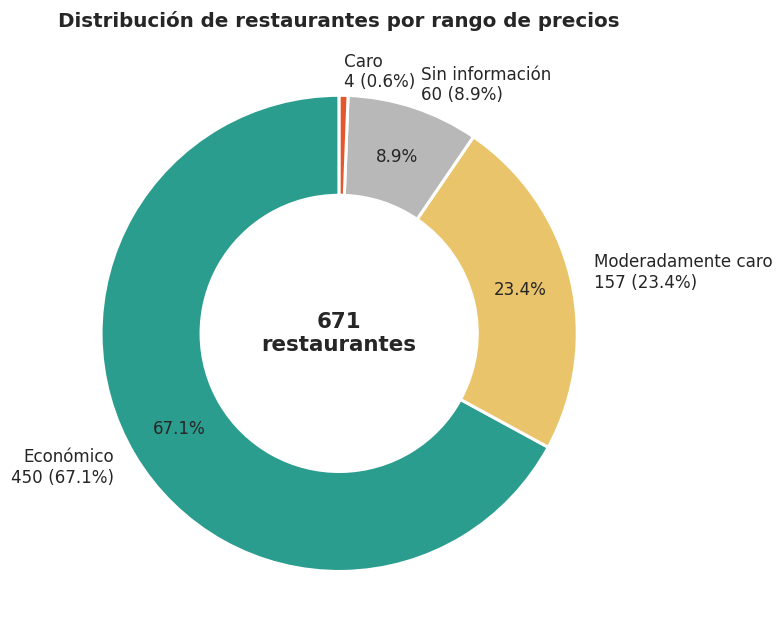

In [20]:
colores = {"Económico": "#2A9D8F", "Moderadamente caro": "#E9C46A", "Caro": "#E4572E",
           "Muy caro": "#9B2226", "Sin información": COLOR_NEUTRO}

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.pie(
    df_q2["total_restaurantes"],
    labels=[f"{r}\n{n} ({p}%)" for r, n, p in zip(df_q2["rango_de_precios"], df_q2["total_restaurantes"], df_q2["porcentaje"])],
    colors=[colores[r] for r in df_q2["rango_de_precios"]],
    autopct=lambda p: f"{p:.1f}%" if p > 5 else "",   # evita solapar la porción diminuta
    startangle=90, pctdistance=0.78,
    wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2),   # <- donut
    textprops={"fontsize": 11},
)
ax.text(0, 0, f"{df_q2['total_restaurantes'].sum():,}\nrestaurantes", ha="center", va="center", fontsize=14, fontweight="bold")
ax.set_title("Distribución de restaurantes por rango de precios")
plt.tight_layout()
plt.show()

> 💡 **Conclusión para el CEO:** la hipótesis es falsa: el 67,1 % de los restaurantes es *Económico* y el 23,4 % *Moderadamente caro*; solo 4 locales (0,6 %) son *Caro* y no hay ninguno *Muy caro* (un 8,9 % no informa precio).

## 🍴 Pregunta 3 · Estrategia de menú por ciudad
**Para las 3 ciudades más populares (P1), ¿cuál es el precio promedio de los platos y dónde es más caro comer?**

In [21]:
query_3 = '''
WITH top_ciudades AS (            -- las 3 ciudades de la Pregunta 1
    SELECT ciudad
    FROM master_food_data
    WHERE ciudad IS NOT NULL
    GROUP BY ciudad
    ORDER BY COUNT(DISTINCT id) DESC, ciudad ASC
    LIMIT 3
)
SELECT ciudad,
       ROUND(AVG(precio), 2)  AS precio_promedio_usd,
       COUNT(*)               AS platos,
       COUNT(DISTINCT id)     AS restaurantes
FROM master_food_data
WHERE ciudad IN (SELECT ciudad FROM top_ciudades)
GROUP BY ciudad
ORDER BY precio_promedio_usd DESC;
'''
df_q3 = ejecutar_query(query_3)
display(df_q3)

🧾 QUERY EJECUTADO:
WITH top_ciudades AS (            -- las 3 ciudades de la Pregunta 1
    SELECT ciudad
    FROM master_food_data
    WHERE ciudad IS NOT NULL
    GROUP BY ciudad
    ORDER BY COUNT(DISTINCT id) DESC, ciudad ASC
    LIMIT 3
)
SELECT ciudad,
       ROUND(AVG(precio), 2)  AS precio_promedio_usd,
       COUNT(*)               AS platos,
       COUNT(DISTINCT id)     AS restaurantes
FROM master_food_data
WHERE ciudad IN (SELECT ciudad FROM top_ciudades)
GROUP BY ciudad
ORDER BY precio_promedio_usd DESC;


,ciudad,precio_promedio_usd,platos,restaurantes
0,Seattle,11.97,9657,119
1,Lynnwood,10.76,3673,42
2,Milwaukee,9.53,11817,123


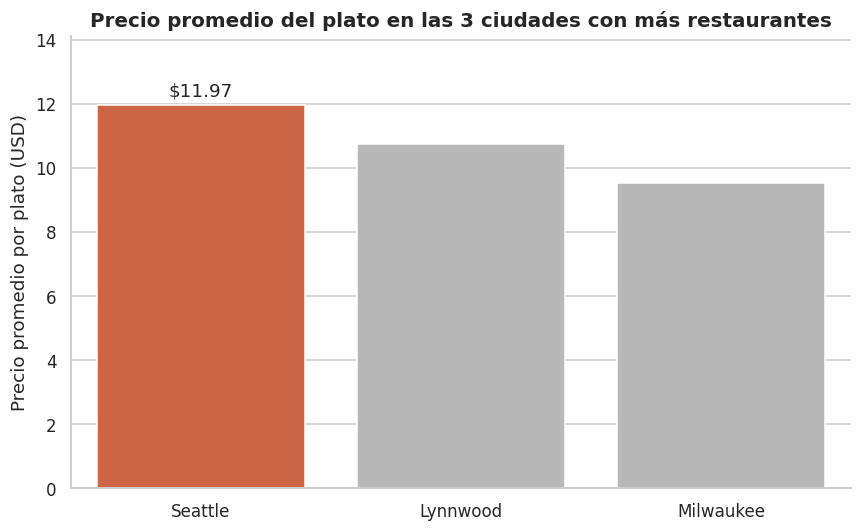

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
colores_q3 = [COLOR_PRINCIPAL] + [COLOR_NEUTRO] * (len(df_q3) - 1)   # resalta la ciudad más cara
sns.barplot(data=df_q3, x="ciudad", y="precio_promedio_usd", hue="ciudad", palette=colores_q3, legend=False, ax=ax)
ax.bar_label(ax.containers[0], fmt="$%.2f", padding=3, fontsize=12)
ax.set_title("Precio promedio del plato en las 3 ciudades con más restaurantes")
ax.set_xlabel("")
ax.set_ylabel("Precio promedio por plato (USD)")
ax.set_ylim(0, df_q3["precio_promedio_usd"].max() * 1.18)
sns.despine()
plt.tight_layout()
plt.show()

> 💡 **Conclusión para el CEO:** Seattle es la ciudad más cara para comer (USD 11,97 por plato en promedio), ≈26 % por encima de Milwaukee (USD 9,53), la más barata; Lynnwood queda en medio con USD 10,76.

## 🏆 Pregunta 4 · La pregunta del millón: correlación precio-calidad
**¿Un restaurante más caro garantiza una mejor experiencia?** Se promedia el `score` por `rango_de_precios`, **una vez por restaurante** (`SELECT DISTINCT`) y excluyendo los que no informan precio.

In [23]:
query_4 = '''
SELECT rango_de_precios,
       ROUND(AVG(score), 3) AS score_promedio,
       COUNT(*)             AS restaurantes
FROM (
    SELECT DISTINCT id, rango_de_precios, score      -- 1 fila por restaurante
    FROM master_food_data
    WHERE rango_de_precios <> 'Sin información'
)
GROUP BY rango_de_precios
ORDER BY CASE rango_de_precios
           WHEN 'Económico'          THEN 1
           WHEN 'Moderadamente caro' THEN 2
           WHEN 'Caro'               THEN 3
           WHEN 'Muy caro'           THEN 4
         END;
'''
df_q4 = ejecutar_query(query_4)
display(df_q4)

🧾 QUERY EJECUTADO:
SELECT rango_de_precios,
       ROUND(AVG(score), 3) AS score_promedio,
       COUNT(*)             AS restaurantes
FROM (
    SELECT DISTINCT id, rango_de_precios, score      -- 1 fila por restaurante
    FROM master_food_data
    WHERE rango_de_precios <> 'Sin información'
)
GROUP BY rango_de_precios
ORDER BY CASE rango_de_precios
           WHEN 'Económico'          THEN 1
           WHEN 'Moderadamente caro' THEN 2
           WHEN 'Caro'               THEN 3
           WHEN 'Muy caro'           THEN 4
         END;


,rango_de_precios,score_promedio,restaurantes
0,Económico,4.616,450
1,Moderadamente caro,4.641,157
2,Caro,4.450,4


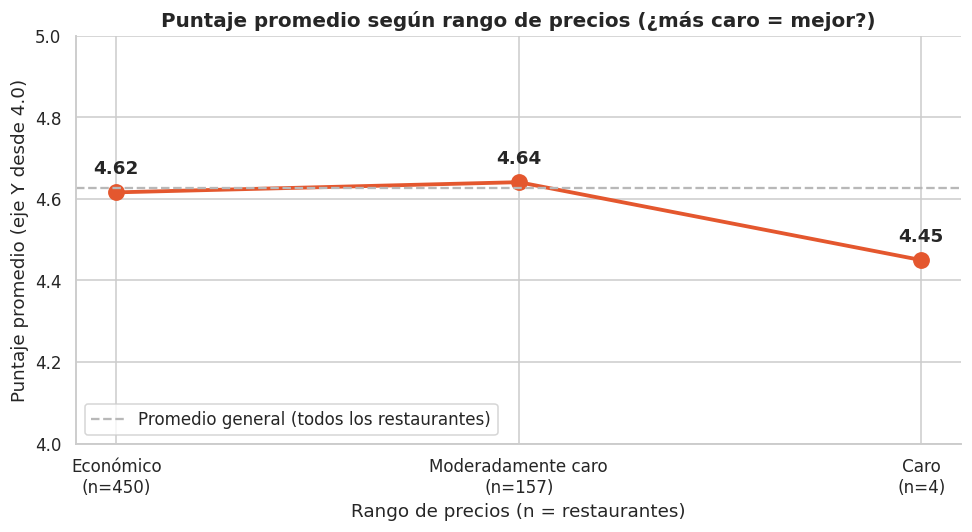

In [24]:
etiquetas = [f"{r}\n(n={n})" for r, n in zip(df_q4["rango_de_precios"], df_q4["restaurantes"])]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(etiquetas, df_q4["score_promedio"], marker="o", markersize=10, linewidth=2.5, color=COLOR_PRINCIPAL)
for x, y in zip(etiquetas, df_q4["score_promedio"]):
    ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 12), ha="center", fontsize=12, fontweight="bold")
ax.set_ylim(4.0, 5.0)
ax.set_title("Puntaje promedio según rango de precios (¿más caro = mejor?)")
ax.set_xlabel("Rango de precios (n = restaurantes)")
ax.set_ylabel("Puntaje promedio (eje Y desde 4.0)")
ax.axhline(df_master.drop_duplicates("id")["score"].mean(), color=COLOR_NEUTRO, linestyle="--", label="Promedio general (todos los restaurantes)")
ax.legend(loc="lower left")
sns.despine()
plt.tight_layout()
plt.show()

> 💡 **Conclusión para el CEO:** no, pagar más no garantiza mejor experiencia: el puntaje es casi idéntico entre *Económico* (4,62) y *Moderadamente caro* (4,64) y baja a 4,45 en *Caro* (solo 4 locales, muestra muy chica).

In [25]:
# Cerramos el motor para liberar el archivo .db
engine.dispose()
print("🔒 Conexión cerrada. Pipeline finalizado.")

🔒 Conexión cerrada. Pipeline finalizado.
